In [105]:
import csv
from pyspark.sql import SparkSession, functions as F
import matplotlib.pyplot as plt
spark = (SparkSession.builder.master("local[*]")
.appName("RDD Exercise").getOrCreate())
sc = spark.sparkContext
CSV_FILES = "/home/jovyan/work/data_Q2_2026"
PARQUET_FILES = "/home/jovyan/work/parquet"
print(spark.version, sc.defaultParallelism)

4.2.0 12


In [7]:
# load only one file at first to infer schema
csv_schema = spark.read.csv(f"{CSV_FILES}/2026-04-01.csv", header=True, inferSchema=True).schema
hard_drives_csv = spark.read.schema(csv_schema).csv(CSV_FILES, header=True)
# convert to parquet
hard_drives_csv.write.mode("overwrite").parquet(PARQUET_FILES)
# read from parquet
hard_drives = spark.read.parquet(PARQUET_FILES)

In [133]:
hard_drives = (
    # map model codes to vendors
    hard_drives.withColumn("vendor", F.expr("""
        CASE 
            WHEN lower(model) LIKE 'toshiba%' THEN 'toshiba'
            WHEN lower(model) LIKE 'seagate%'     THEN 'seagate'
            WHEN lower(model) LIKE 'st%'          THEN 'seagate'
            WHEN lower(model) LIKE 'wd%'          THEN 'western digital'
            WHEN lower(model) LIKE 'hgst%'        THEN 'western digital'
            WHEN lower(model) LIKE 'wdc%'         THEN 'western digital'
            WHEN lower(model) LIKE 'wuh%'         THEN 'western digital'
            WHEN lower(model) LIKE 'ct%'          THEN 'crucial'
            WHEN lower(model) LIKE 'mtf%'         THEN 'micron'
            WHEN lower(model) LIKE 'micron%'      THEN 'micron'
            WHEN lower(model) LIKE 'samsung%'     THEN 'samsung'
            WHEN lower(model) LIKE 'ssdsckkb%'    THEN 'dell'
            WHEN lower(model) LIKE 'dellboss vd%' THEN 'virtual drive'
            ELSE 'other'
        END
    """)
                 )\
    # synthetic columns for analysis
        .withColumn("power_on_days", F.col("smart_9_raw") / 24)
        .withColumn("capacity_kilobytes", F.col("capacity_bytes") / 1000)
        .withColumn("capacity_megabytes", F.col("capacity_kilobytes") / 1000)
        .withColumn("capacity_gigabytes", F.col("capacity_megabytes") / 1000)
        .withColumn("capacity_gigabytes_rounded", F.round(F.col("capacity_gigabytes"), 0))
        .withColumn("capacity_terrabytes", F.col("capacity_gigabytes") / 1000)
        .withColumn("capacity_terrabytes_rounded", F.round(F.col("capacity_terrabytes"), 0))
)

In [130]:
# Check failures per vendor along with some statistics
hard_drives.filter(hard_drives["failure"] == 1)\
    .groupBy("vendor")\
    .agg(F.count(F.lit(1)).alias("Num Of Failures"), \
         F.min("power_on_days").alias("Min Power-On days"), \
         F.max("power_on_days").alias("Max Power-On days"), \
         F.median("power_on_days").alias("Median Power-On days"), \
         F.avg("power_on_days").alias("Average Power-On days"), \
         F.std("power_on_days").alias("Standard deviation Power-On days"), \
        )\
    .show()

+---------------+---------------+------------------+------------------+--------------------+---------------------+--------------------------------+
|         vendor|Num Of Failures| Min Power-On days| Max Power-On days|Median Power-On days|Average Power-On days|Standard deviation Power-On days|
+---------------+---------------+------------------+------------------+--------------------+---------------------+--------------------------------+
|western digital|            511| 5.291666666666667|3314.6666666666665|  1858.7083333333333|   1770.1382093933466|               773.5128489521135|
|        toshiba|            428|2.7916666666666665|2815.4166666666665|  1676.0208333333333|   1517.3582554517134|                767.830134877637|
|        seagate|            583|               0.0|3255.0416666666665|  2033.4583333333335|   1704.4666370106763|              1042.4978402871473|
+---------------+---------------+------------------+------------------+--------------------+--------------------

In [128]:
# find outlier for seagate
outliers = hard_drives.filter(hard_drives["failure"] == 1)\
    .filter(hard_drives["smart_9_raw"] == 0) \
    .select("serial_number")
# check accross all entries to see if it really failed immediately
hard_drives.join(outliers, on="serial_number")\
    .select("date", "serial_number", "model", "vendor", "capacity_bytes")\
    .show()

+----------+-------------+-------------+-------+--------------+
|      date|serial_number|        model| vendor|capacity_bytes|
+----------+-------------+-------------+-------+--------------+
|2026-05-05|     ZYDG713B|ST24000NM002H|seagate|24000277250048|
+----------+-------------+-------------+-------+--------------+



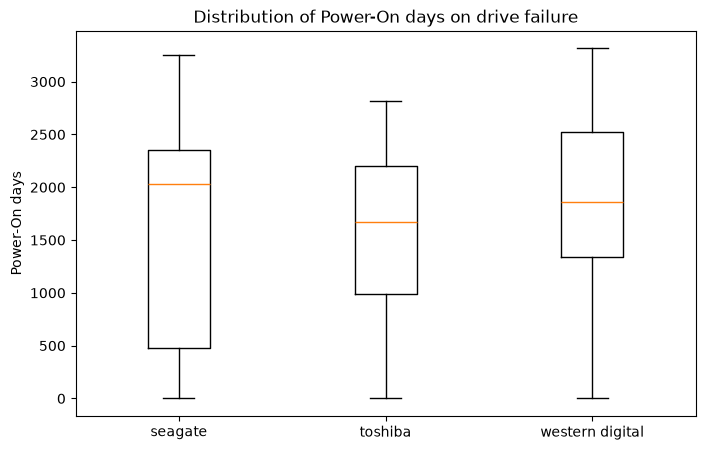

In [129]:
# boxplot for presentation
boxplot_stats = hard_drives.filter(hard_drives["failure"] == 1)\
    .groupBy("vendor")\
    .agg(
        F.min("power_on_days").alias("min_val"),
        F.percentile_approx("power_on_days", [0.25, 0.5, 0.75], 10000).alias("q"),
        F.max("power_on_days").alias("max_val")
    )\
    .select(
        "vendor",
        F.col("min_val"),
        F.col("q")[0].alias("q1"),
        F.col("q")[1].alias("med"),
        F.col("q")[2].alias("q3"),
        F.col("max_val")
    )\
    .withColumn("iqr", F.col("q3") - F.col("q1"))\
    .withColumn("whislo", F.greatest(F.col("min_val"), F.col("q1") - 1.5 * F.col("iqr")))\
    .withColumn("whishi", F.least(F.col("max_val"), F.col("q3") + 1.5 * F.col("iqr")))

rows = boxplot_stats.orderBy("vendor").collect()

bxp_stats = [
    {
        "label": r["vendor"],
        "whislo": r["whislo"],
        "q1": r["q1"],
        "med": r["med"],
        "q3": r["q3"],
        "whishi": r["whishi"],
    }
    for r in rows
]

fig, ax = plt.subplots(figsize=(8, 5))
ax.bxp(bxp_stats, showfliers=False)
ax.set_ylabel("Power-On days")
ax.set_title("Distribution of Power-On days on drive failure")
plt.show()

In [154]:
agg = hard_drives.groupBy("serial_number")\
    .agg(F.first("capacity_gigabytes_rounded").alias("first"), F.last("capacity_gigabytes_rounded").alias("last"), F.avg("capacity_gigabytes_rounded").alias("avg"))\

# confirm that capacity remains the same across all entries for a serial_number
agg.filter(agg["first"] != agg["last"])\
   .filter(agg["first"] != agg["avg"])\
   .filter(agg["last"] != agg["avg"])\
   .show()

+-------------+-----+----+---+
|serial_number|first|last|avg|
+-------------+-----+----+---+
+-------------+-----+----+---+



In [162]:
drives_grouped_by_serial_number = hard_drives.groupBy("serial_number")\
    .agg(
         F.first("vendor").alias("vendor"), \
         F.first("capacity_gigabytes_rounded").alias("capacity_gigabytes_rounded"), \
         F.first("capacity_terrabytes_rounded").alias("capacity_terrabytes_rounded"), \
         F.max("failure").alias("failed"), \
         F.max("power_on_days").alias("power_on_days") \
    )

In [163]:
drives_grouped_by_serial_number\
    .groupBy("vendor")\
    .agg(F.count(F.lit(1)).alias("Num"), \
         F.min("capacity_gigabytes_rounded").alias("Min capacity in GB"), \
         F.max("capacity_gigabytes_rounded").alias("Max capacity in GB"), \
         F.median("capacity_gigabytes_rounded").alias("Median capacity in GB"), \
        )\
    .show()

+---------------+------+------------------+------------------+---------------------+
|         vendor|   Num|Min capacity in GB|Max capacity in GB|Median capacity in GB|
+---------------+------+------------------+------------------+---------------------+
|western digital|117490|             250.0|           26001.0|              16001.0|
|        toshiba|125382|             500.0|           24000.0|              16001.0|
|         micron|    96|             240.0|             480.0|                240.0|
|        seagate|114989|             250.0|           24000.0|              14001.0|
|        crucial|   704|             250.0|             250.0|                250.0|
|  virtual drive|   431|             480.0|             480.0|                480.0|
|        samsung|     7|            1000.0|            2048.0|               2000.0|
|           dell|     2|             240.0|             480.0|                360.0|
+---------------+------+------------------+------------------+---

In [165]:
drives_grouped_by_serial_number\
    .filter(drives_grouped_by_serial_number["failed"] == 1)\
    .groupBy("capacity_gigabytes_rounded")\
    .agg(F.count(F.lit(1)).alias("Num"), \
         F.min("power_on_days").alias("Min Power-On days"), \
         F.max("power_on_days").alias("Max Power-On days"), \
         F.median("power_on_days").alias("Median Power-On days"), \
         F.avg("power_on_days").alias("Average Power-On days"), \
         F.std("power_on_days").alias("Standard deviation Power-On days"), \
        )\
    .orderBy("capacity_gigabytes_rounded")\
    .show()

+--------------------------+---+------------------+------------------+--------------------+---------------------+--------------------------------+
|capacity_gigabytes_rounded|Num| Min Power-On days| Max Power-On days|Median Power-On days|Average Power-On days|Standard deviation Power-On days|
+--------------------------+---+------------------+------------------+--------------------+---------------------+--------------------------------+
|                    8002.0|152|11.791666666666666|3314.6666666666665|           3155.8125|   1907.4141995614034|               1451.104552110575|
|                   10001.0| 23|          1229.375|3211.6666666666665|            3139.875|   3065.2047101449275|              400.77595918703247|
|                   12000.0|497| 383.7916666666667|           2769.75|  2314.2916666666665|   2232.6675888665322|              366.39823612070455|
|                   14001.0|273|228.95833333333334|2815.4166666666665|   2073.145833333333|    2119.258884803922|     

In [166]:
# The query above makes it seem like larger drives fail a lot sooner, but that statistic is skewed, because backblaze has been using ~10TB drives
# for a lot longer than ~20TB bytes, so the comparison isn't fair as the average age of the smaller drives is a lot older than for the larger ones.
# This can be seen by running the query again but without the filter for the failed drives.
drives_grouped_by_serial_number\
    .groupBy("capacity_gigabytes_rounded")\
    .agg(F.count(F.lit(1)).alias("Num"), \
         F.min("power_on_days").alias("Min Power-On days"), \
         F.max("power_on_days").alias("Max Power-On days"), \
         F.median("power_on_days").alias("Median Power-On days"), \
         F.avg("power_on_days").alias("Average Power-On days"), \
         F.std("power_on_days").alias("Standard deviation Power-On days"), \
        )\
    .orderBy("capacity_gigabytes_rounded")\
    .show()

+--------------------------+------+-------------------+------------------+--------------------+---------------------+--------------------------------+
|capacity_gigabytes_rounded|   Num|  Min Power-On days| Max Power-On days|Median Power-On days|Average Power-On days|Standard deviation Power-On days|
+--------------------------+------+-------------------+------------------+--------------------+---------------------+--------------------------------+
|                     240.0|    87| 1229.5416666666667|2076.8333333333335|  2049.1666666666665|   2032.0062260536397|               89.37664355130711|
|                     250.0|  2876|0.16666666666666666|4026.0416666666665|  1772.2083333333335|   1624.7735280482154|               652.6925952278918|
|                     480.0|   442| 34.166666666666664|1306.9583333333333|   456.7916666666667|    619.3219696969696|               545.7627426016925|
|                     500.0|   544| 1020.3333333333334| 4808.958333333333|              3062.5